In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import numpy as np
import pandas as pd

In [3]:
url = "https://zenodo.org/records/5898311/files/vgsales.csv"

data = pd.read_csv(url)

data.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [4]:
(0,3),(1,5),(2,9)

((0, 3), (1, 5), (2, 9))

In [5]:
x_val=[0,1,2]
y_val=[3,5,9]

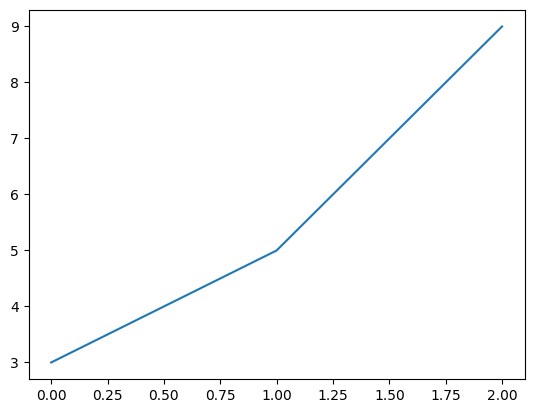

In [6]:
plt.plot(x_val,y_val)

In [7]:
 data['Genre']

,Genre
0,Sports
1,Platform
2,Racing
3,Sports
4,Role-Playing
...,...
16593,Platform
16594,Shooter
16595,Racing
16596,Puzzle


In [8]:
data['Genre'].unique()

array(['Sports', 'Platform', 'Racing', 'Role-Playing', 'Puzzle', 'Misc',
       'Shooter', 'Simulation', 'Action', 'Fighting', 'Adventure',
       'Strategy'], dtype=object)

In [9]:
cat_counts=data['Genre'].value_counts()

In [10]:
cat_counts

,count
Genre,
Action,3316
Sports,2346
Misc,1739
Role-Playing,1488
Shooter,1310
Adventure,1286
Racing,1249
Platform,886
Simulation,867


In [11]:
X_bar=cat_counts.index
Y_bar=cat_counts.values

<BarContainer object of 12 artists>

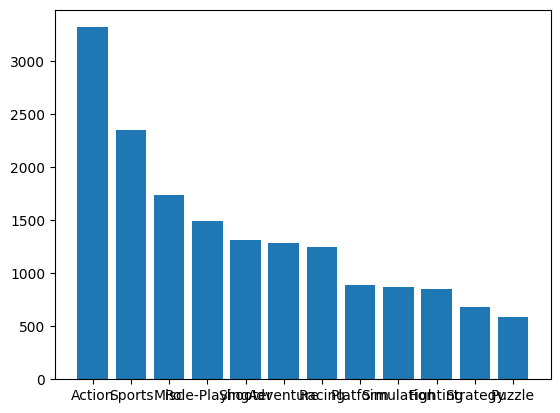

In [12]:
plt.bar(X_bar,Y_bar)

<BarContainer object of 12 artists>

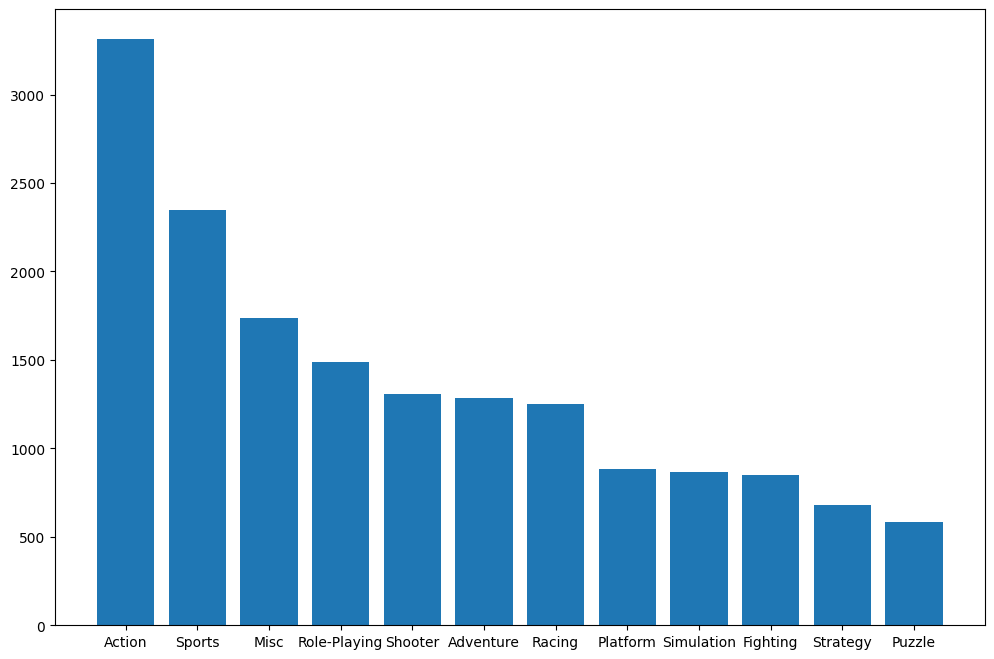

In [13]:
plt.figure(figsize=(12,8))
plt.bar(X_bar,Y_bar)

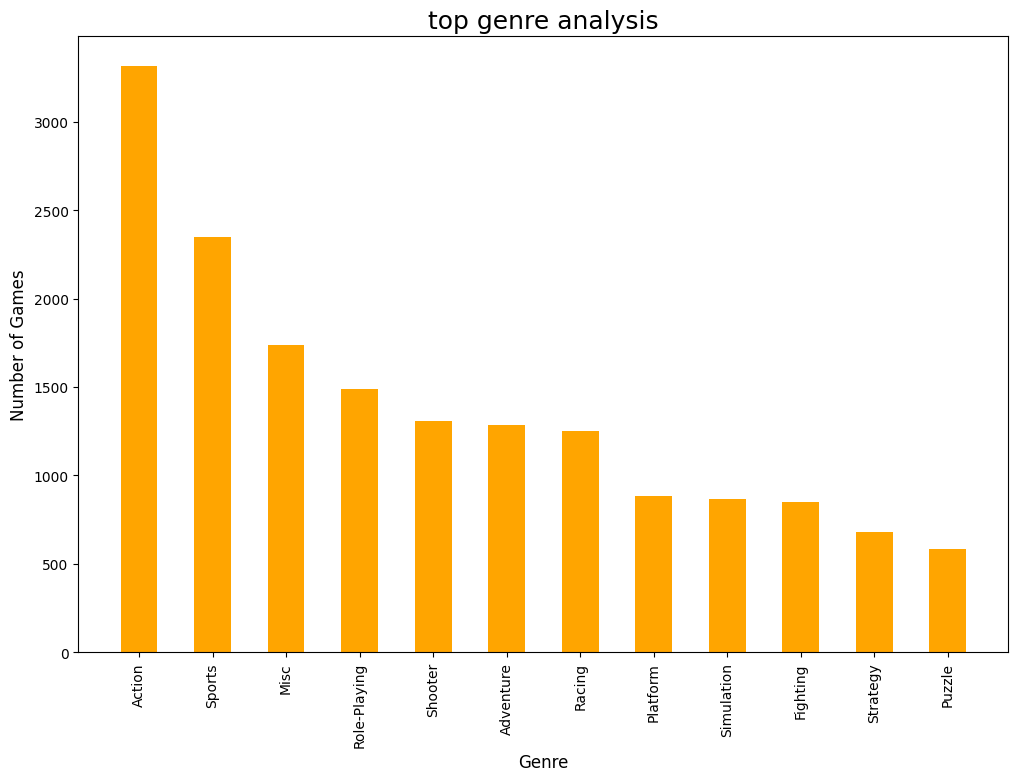

In [14]:
plt.figure(figsize=(12,8))
plt.xticks(rotation=90,fontsize=10)
plt.bar(X_bar,Y_bar,width=0.5,color='orange')
plt.xlabel('Genre',fontsize=12)
plt.ylabel('Number of Games',fontsize=12)
plt.title('top genre analysis',fontsize=18)
plt.show()

<Axes: xlabel='Genre', ylabel='count'>

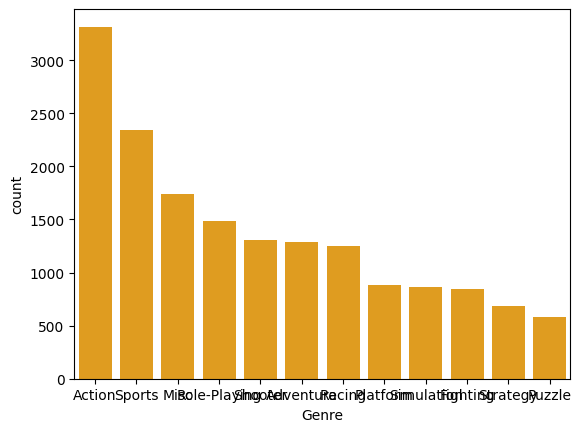

In [15]:
sns.countplot(x='Genre',data=data,order=data['Genre'].value_counts().index,color='orange')

In [16]:
sales_data=data[['NA_Sales','EU_Sales','JP_Sales','Other_Sales']]

In [17]:
sales_data

,NA_Sales,EU_Sales,JP_Sales,Other_Sales
0,41.49,29.02,3.77,8.46
1,29.08,3.58,6.81,0.77
2,15.85,12.88,3.79,3.31
3,15.75,11.01,3.28,2.96
4,11.27,8.89,10.22,1.00
...,...,...,...,...
16593,0.01,0.00,0.00,0.00
16594,0.01,0.00,0.00,0.00
16595,0.00,0.00,0.00,0.00
16596,0.00,0.01,0.00,0.00


In [18]:
region_sales=sales_data.T.sum(axis='columns')

In [19]:
region_sales

,0
NA_Sales,4392.95
EU_Sales,2434.13
JP_Sales,1291.02
Other_Sales,797.75


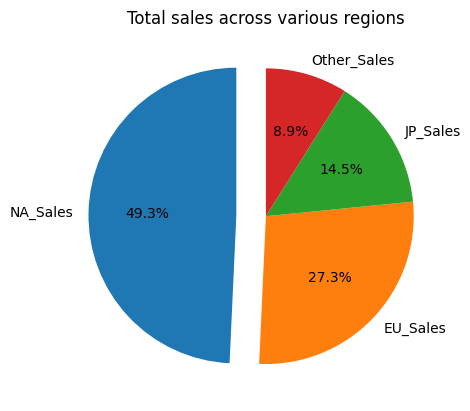

In [20]:
plt.pie(region_sales,labels=region_sales.index,startangle=90,explode=(0.2,0,0,0),autopct='%1.1f%%')
plt.title("Total sales across various regions")
plt.show()

In [21]:
data.describe()

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16327.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
mean,8300.605254,2006.406443,0.264667,0.146652,0.077782,0.048063,0.537441
std,4791.853933,5.828981,0.816683,0.505351,0.309291,0.188588,1.555028
min,1.000000,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.470000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


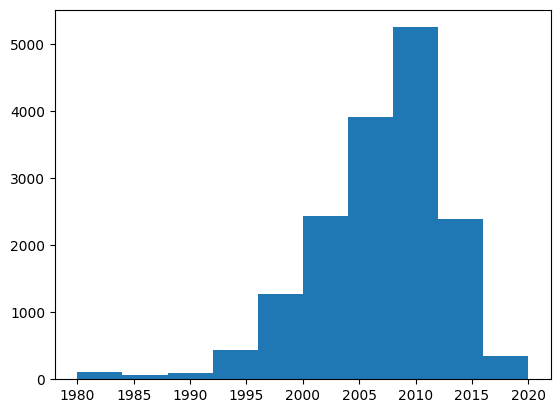

In [22]:
plt.hist(data['Year'])
plt.show()

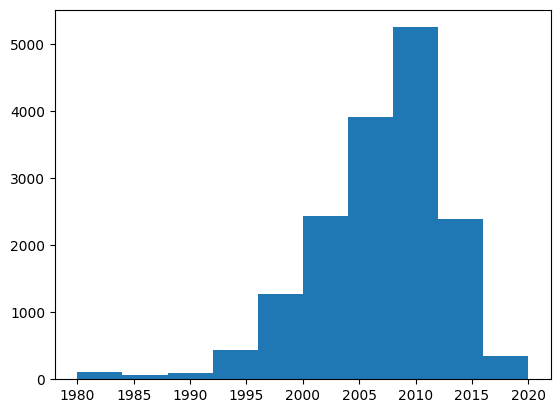

In [23]:
count,bins, _=plt.hist(data['Year'])

<Axes: xlabel='Year', ylabel='Count'>

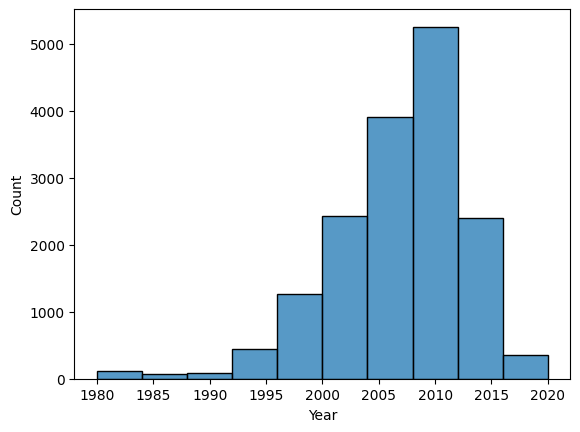

In [24]:
sns.histplot(data['Year'],bins=10)

<Axes: xlabel='Year', ylabel='Density'>

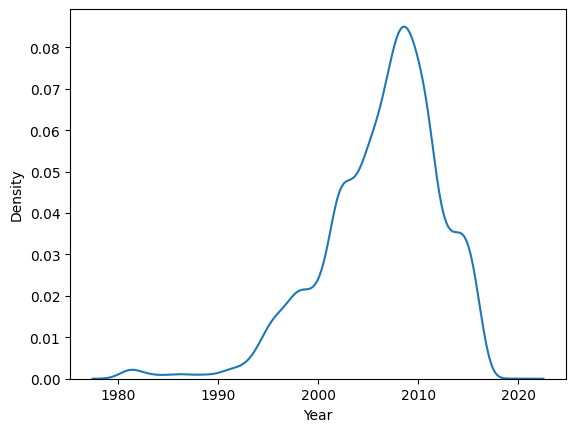

In [25]:
sns.kdeplot(data['Year'])

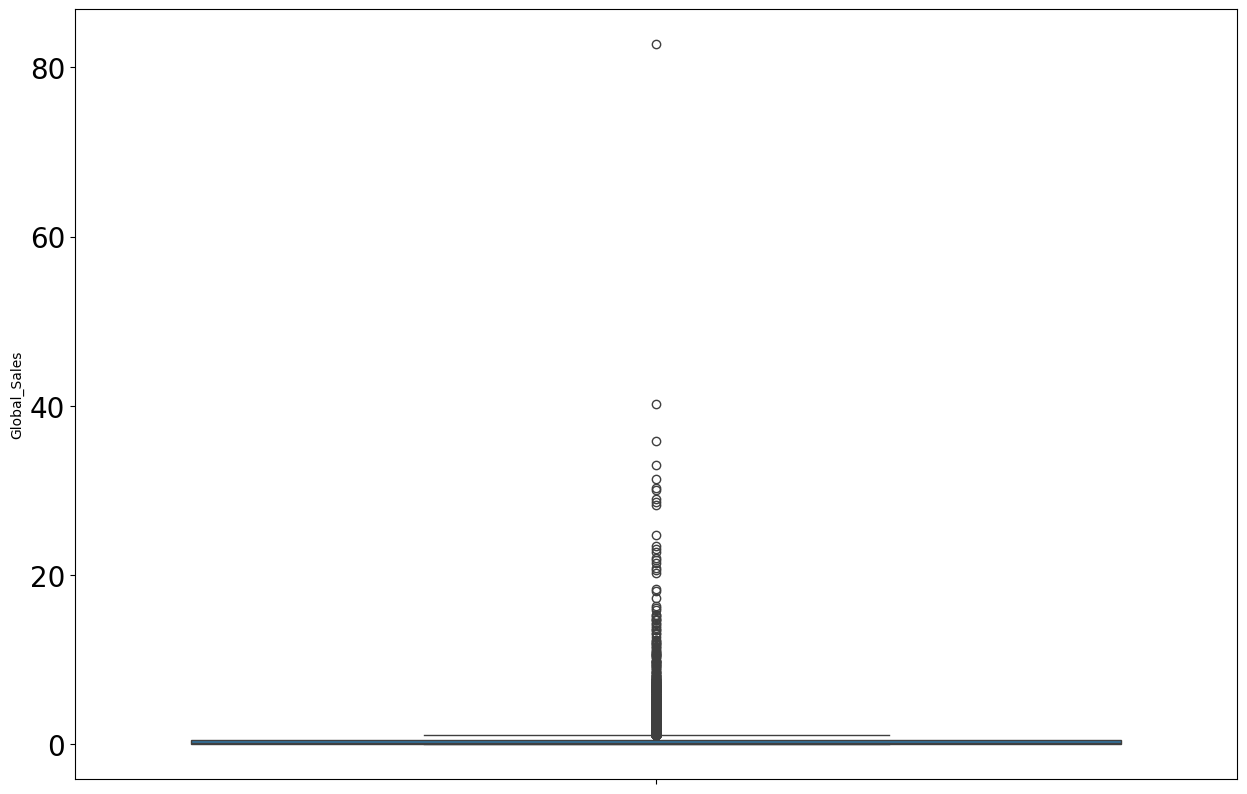

In [26]:
plt.figure(figsize=(15, 10))

sns.boxplot(y=data['Global_Sales'])

plt.yticks(fontsize=20)
plt.show()

In [30]:
a = data.groupby('Year', as_index=False)['Global_Sales'].sum()

<Axes: xlabel='Year', ylabel='Global_Sales'>

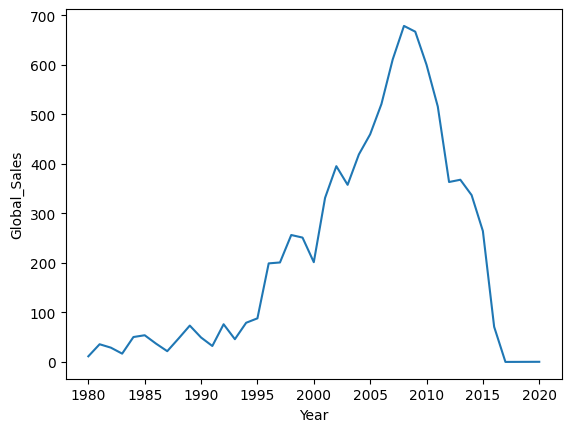

In [32]:
sns.lineplot(data=a,x='Year',y='Global_Sales')

In [33]:
print(a.shape)
print(a[['Year','Global_Sales']].head(10))
print(a[['Year','Global_Sales']].dtypes)
print(a[['Year','Global_Sales']].isna().sum())
print(a['Year'].nunique())

(39, 2)
     Year  Global_Sales
0  1980.0         11.38
1  1981.0         35.77
2  1982.0         28.86
3  1983.0         16.79
4  1984.0         50.36
5  1985.0         53.94
6  1986.0         37.07
7  1987.0         21.74
8  1988.0         47.22
9  1989.0         73.45
Year            float64
Global_Sales    float64
dtype: object
Year            0
Global_Sales    0
dtype: int64
39


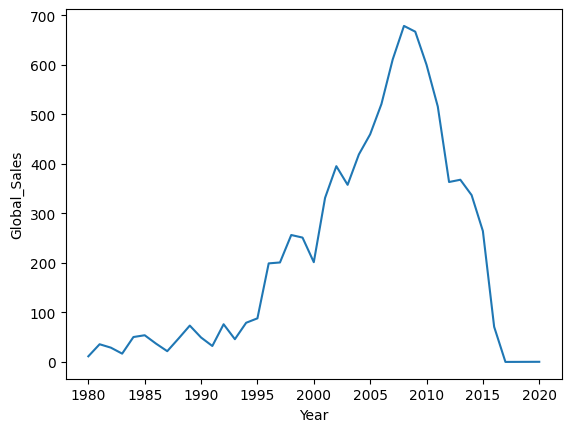

In [34]:
yearly = data.groupby('Year', as_index=False)['Global_Sales'].sum()
sns.lineplot(data=yearly, x='Year', y='Global_Sales')
plt.show()

In [35]:
data['Name'].value_counts()

,count
Name,
Need for Speed: Most Wanted,12
LEGO Marvel Super Heroes,9
Ratatouille,9
Madden NFL 07,9
FIFA 14,9
...,...
Afrika,1
Blue Dragon Plus,1
Ninja Gaiden: Dragon Sword,1


In [36]:
b=data.loc[data['Name']=='Need for Speed: Most Wanted']

In [37]:
b.shape

(12, 11)

<Axes: xlabel='Year', ylabel='NA_Sales'>

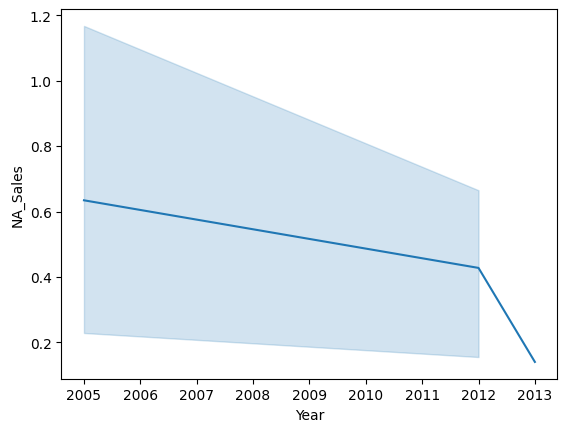

In [38]:
sns.lineplot(data=b,x='Year',y='NA_Sales')

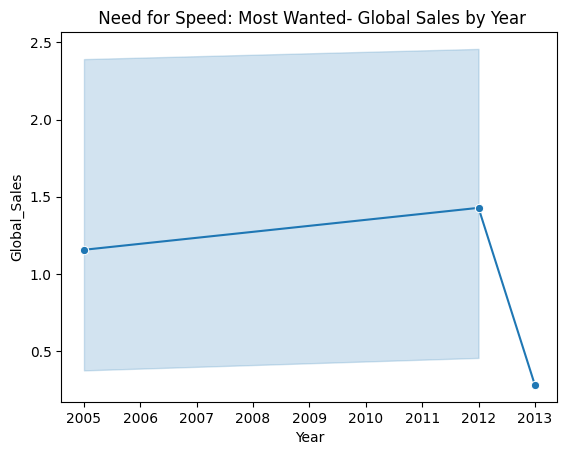

In [39]:
sns.lineplot(data=b, x='Year', y='Global_Sales', marker='o')
plt.title(' Need for Speed: Most Wanted- Global Sales by Year')
plt.show()

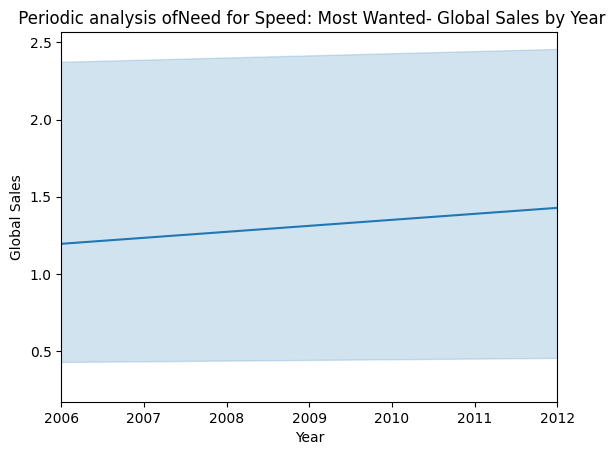

In [40]:
plt.xlabel('Year')
plt.ylabel('Global Sales')
plt.title(' Periodic analysis ofNeed for Speed: Most Wanted- Global Sales by Year')
plt.xlim(left=2006,right=2012)
sns.lineplot(data=b,x='Year',y='Global_Sales')
plt.show()

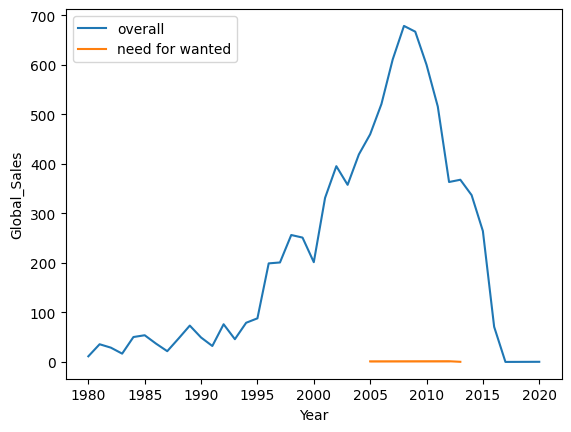

In [41]:
sns.lineplot(data=yearly, x='Year', y='Global_Sales',label='overall')
sns.lineplot(data=b,x='Year',y='Global_Sales',label='need for wanted')
plt.legend(loc='upper left')

<Axes: xlabel='Year', ylabel='Global_Sales'>

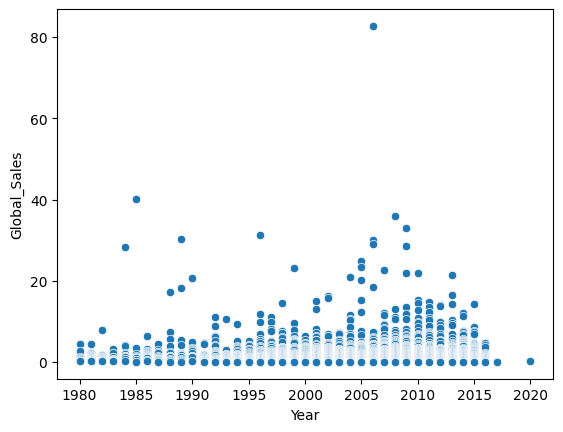

In [42]:
sns.scatterplot(data=data,x='Year',y='Global_Sales')

<Axes: xlabel='Rank', ylabel='NA_Sales'>

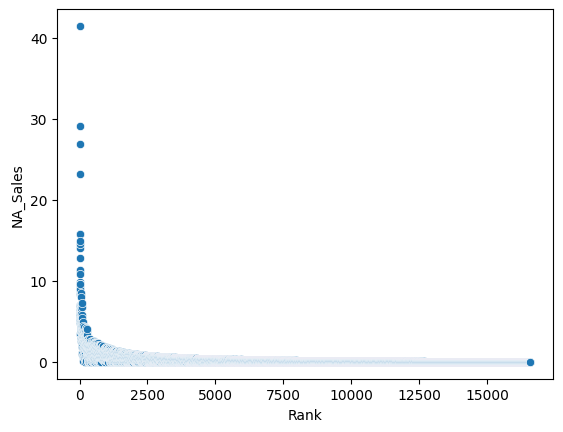

In [43]:
sns.scatterplot(data=data,x='Rank',y='NA_Sales')

In [44]:
data['Publisher'].value_counts()

,count
Publisher,
Electronic Arts,1351
Activision,975
Namco Bandai Games,932
Ubisoft,921
Konami Digital Entertainment,832
...,...
Media Entertainment,1
New World Computing,1
Genterprise,1


<Axes: xlabel='Publisher', ylabel='count'>

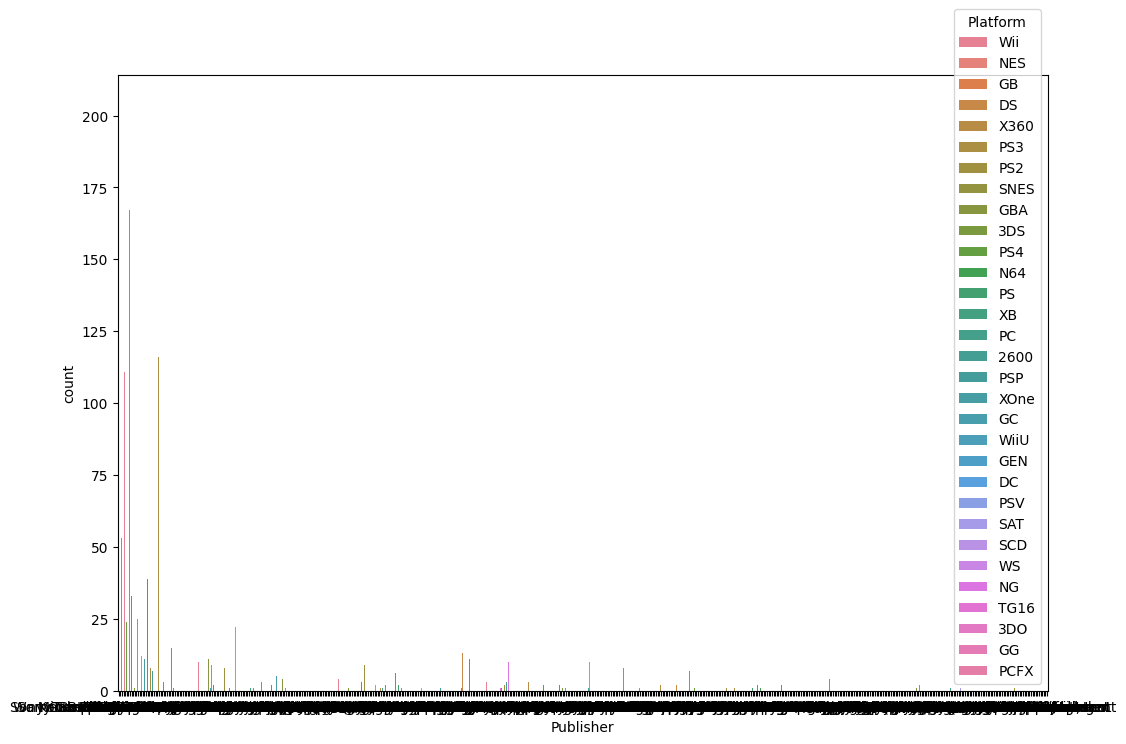

In [45]:
plt.figure(figsize=(12,8))
sns.countplot(x='Publisher',data=data,hue='Platform')


In [46]:
top5_pub=data['Publisher'].value_counts().index[:3]

In [47]:
top_5genre=data['Genre'].value_counts().index[:3]

In [48]:
top_5_plat=data['Platform'].value_counts().index[:3]

In [49]:
top_5_plat

Index(['DS', 'PS2', 'PS3'], dtype='object', name='Platform')

In [50]:
top_5_data=data.loc[(data['Publisher'].isin(top5_pub)& (data['Platform'].isin(top_5_plat))&(data['Genre'].isin(top_5genre)))]

In [51]:
top_5_data

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
82,83,FIFA Soccer 13,PS3,2012.0,Action,Electronic Arts,1.06,5.05,0.13,2.01,8.24
112,113,FIFA 14,PS3,2013.0,Sports,Electronic Arts,0.78,4.32,0.07,1.73,6.90
121,122,FIFA 12,PS3,2011.0,Sports,Electronic Arts,0.84,4.32,0.11,1.42,6.69
179,180,Madden NFL 2004,PS2,NaN,Sports,Electronic Arts,4.26,0.26,0.01,0.71,5.23
199,200,FIFA Soccer 11,PS3,2010.0,Sports,Electronic Arts,0.60,3.29,0.06,1.13,5.08
...,...,...,...,...,...,...,...,...,...,...,...
16102,16105,Tobidase! Kagaku-kun Chikyuu Daitanken! Nazo n...,DS,2011.0,Misc,Namco Bandai Games,0.00,0.00,0.01,0.00,0.01
16127,16130,Madden NFL 13,PS3,2012.0,Sports,Electronic Arts,0.00,0.01,0.00,0.00,0.01
16215,16218,Tsukigime Ranko's Longest Day,PS3,2014.0,Action,Namco Bandai Games,0.00,0.01,0.00,0.00,0.01
16523,16526,Style Book: Cinnamoroll,DS,2006.0,Misc,Namco Bandai Games,0.00,0.00,0.01,0.00,0.01


<Axes: xlabel='Publisher', ylabel='count'>

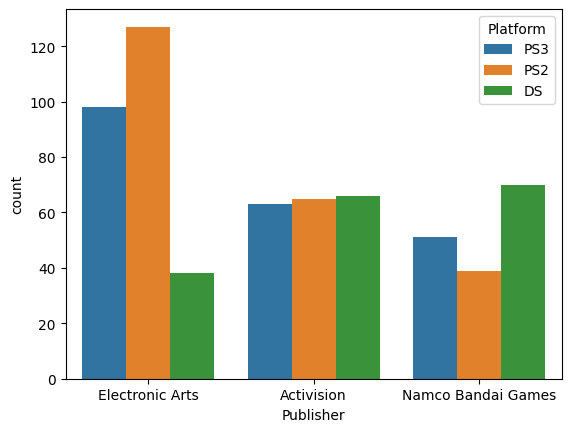

In [52]:
sns.countplot(top_5_data,x='Publisher',hue='Platform')

<Axes: xlabel='Publisher', ylabel='Global_Sales'>

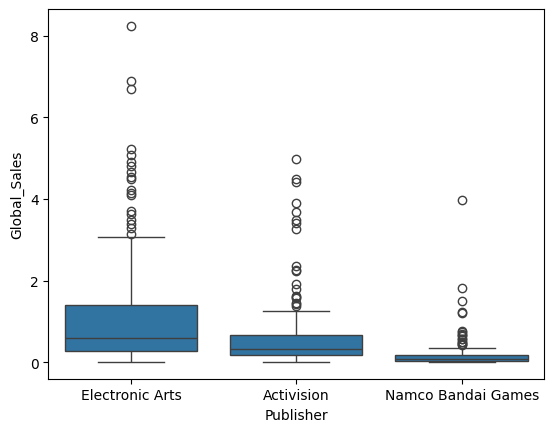

In [53]:
sns.boxplot(x='Publisher',y='Global_Sales',data=top_5_data)

In [56]:
top_5_data=top_5_data.select_dtypes(include='number')

In [57]:
top_5_data

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
82,83,2012.0,1.06,5.05,0.13,2.01,8.24
112,113,2013.0,0.78,4.32,0.07,1.73,6.90
121,122,2011.0,0.84,4.32,0.11,1.42,6.69
179,180,NaN,4.26,0.26,0.01,0.71,5.23
199,200,2010.0,0.60,3.29,0.06,1.13,5.08
...,...,...,...,...,...,...,...
16102,16105,2011.0,0.00,0.00,0.01,0.00,0.01
16127,16130,2012.0,0.00,0.01,0.00,0.00,0.01
16215,16218,2014.0,0.00,0.01,0.00,0.00,0.01
16523,16526,2006.0,0.00,0.00,0.01,0.00,0.01


<Axes: >

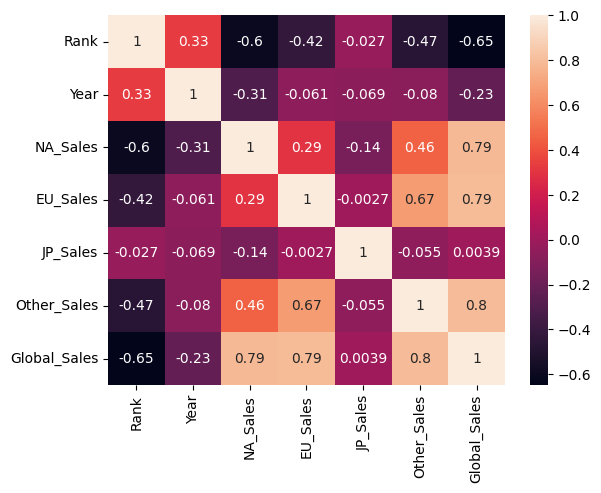

In [58]:
sns.heatmap(top_5_data.corr(),annot=True)

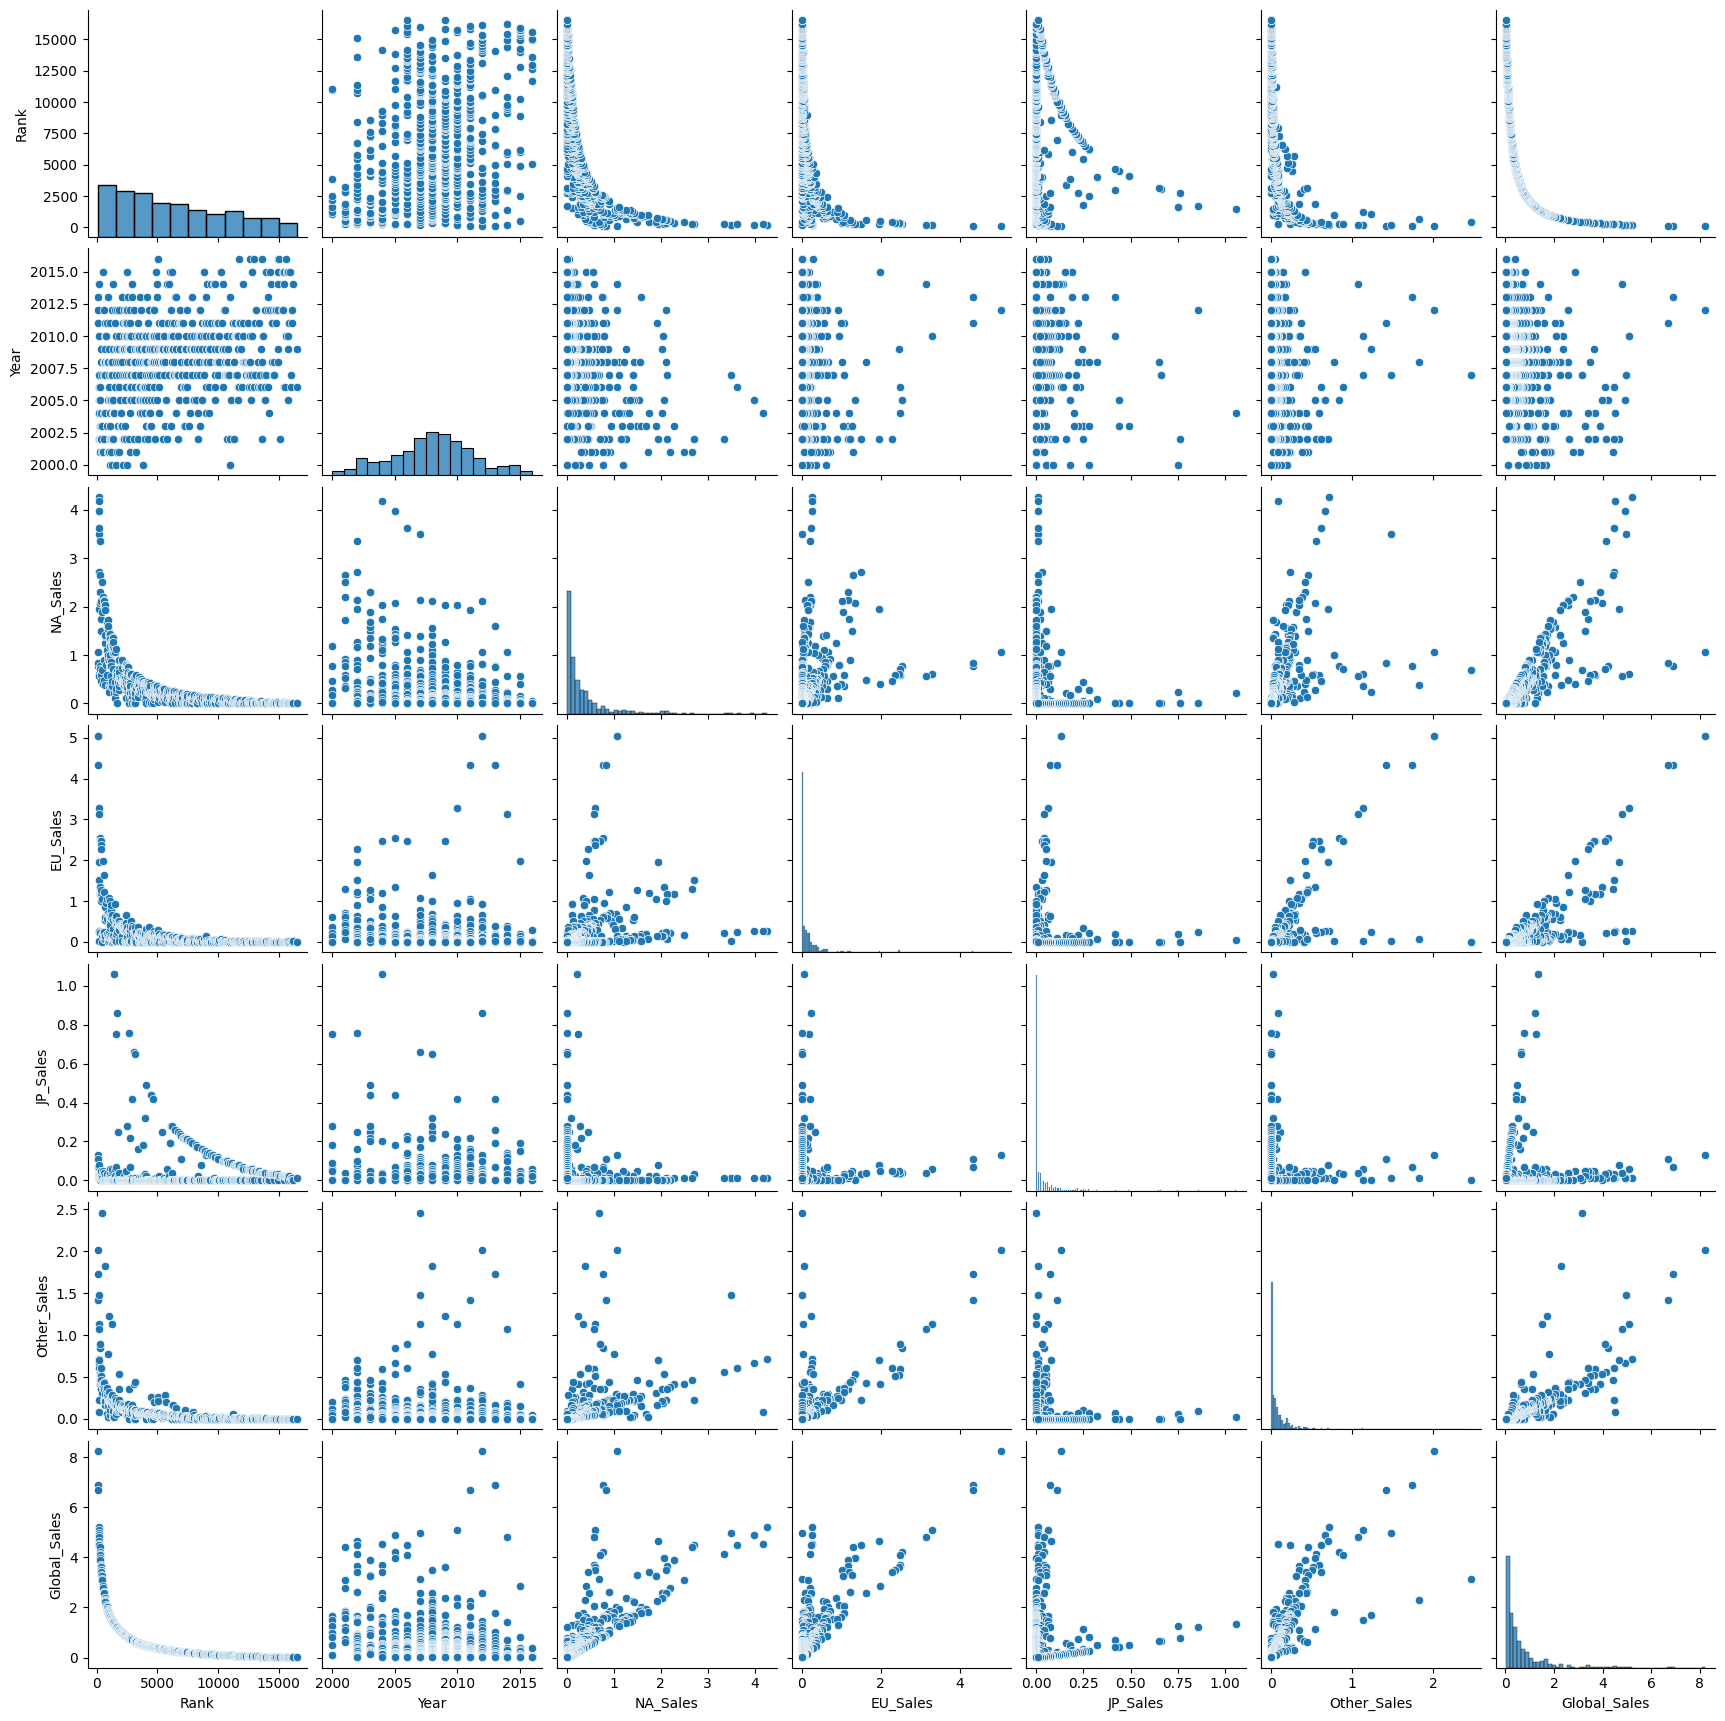

In [59]:
sns.pairplot(top_5_data)